# IDX Market & Portfolio Risk Analysis

How have Indonesia's large-cap stocks behaved from January 2021 to October 2026, and what does that mean
for a portfolio? This notebook measures return, risk and co-movement for 10 liquid IDX stocks across
5 sectors against the Jakarta Composite Index (IHSG). It then builds portfolios and stress-tests
them with Monte Carlo simulation.

**Data:** daily adjusted close prices from Yahoo Finance (public), fetched at run time. No data is stored in this repository.

**Contents**
1. Data & cleaning
2. Performance vs IHSG
3. Risk metrics: volatility, Sharpe, max drawdown, beta
4. Correlation & diversification
5. Rolling volatility (regime changes)
6. Portfolio construction: 20,000 random portfolios → efficient frontier
7. Monte Carlo value-at-risk for a 1-year horizon
8. Findings

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yfinance as yf

plt.rcParams.update({"figure.figsize": (11, 5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.options.display.float_format = "{:,.3f}".format
RNG = np.random.default_rng(42)
TRADING_DAYS = 252
RISK_FREE = 0.06   # approx. Bank Indonesia policy rate range over the period

## 1. Data & cleaning

In [2]:
SECTORS = {
    "BBCA": "Banks", "BBRI": "Banks", "BMRI": "Banks",
    "TLKM": "Telco", "ASII": "Industrials",
    "ANTM": "Mining", "ADRO": "Mining",
    "UNVR": "Consumer", "ICBP": "Consumer",
    "GOTO": "Tech",
}
tickers = [f"{t}.JK" for t in SECTORS] + ["^JKSE"]

cache = Path("data/prices.csv")
if cache.exists():
    prices = pd.read_csv(cache, index_col=0, parse_dates=True)
else:
    raw = yf.download(tickers, start="2021-01-01", end="2026-11-01", auto_adjust=True, progress=False)
    prices = raw["Close"].rename(columns=lambda c: c.replace(".JK", "").replace("^JKSE", "IHSG"))
    cache.parent.mkdir(exist_ok=True)
    prices.to_csv(cache)

prices = prices[list(SECTORS) + ["IHSG"]]
print(prices.shape, prices.index.min().date(), "->", prices.index.max().date())
prices.isna().sum().to_frame("missing_days").T

(1403, 11) 2021-01-04 -> 2026-10-30


,BBCA,BBRI,BMRI,TLKM,ASII,ANTM,ADRO,UNVR,ICBP,GOTO,IHSG
missing_days,0,0,0,0,0,0,0,0,0,314,0


GOTO only listed in April 2022, which explains its missing days. The rest have none.
I keep GOTO in the per-stock analysis on its own history. Analyses that need a common window
(correlation, portfolios) use **daily log returns from the first date when all stocks traded**.

In [3]:
rets = np.log(prices / prices.shift(1)).iloc[1:]
common = rets.dropna()
print("full window days:", len(rets), "| common window days:", len(common), "from", common.index.min().date())
rets.describe().T[["mean", "std", "min", "max"]]

full window days: 1402 | common window days: 1088 from 2022-04-12


,mean,std,min,max
BBCA,-0.000,0.017,-0.160,0.093
BBRI,0.000,0.019,-0.161,0.094
BMRI,0.000,0.020,-0.160,0.098
TLKM,-0.000,0.021,-0.161,0.152
ASII,0.000,0.020,-0.132,0.129
ANTM,0.000,0.030,-0.159,0.163
ADRO,0.001,0.027,-0.283,0.177
UNVR,-0.001,0.025,-0.167,0.157
ICBP,-0.000,0.017,-0.098,0.095
GOTO,-0.003,0.038,-0.228,0.299


## 2. Performance vs IHSG

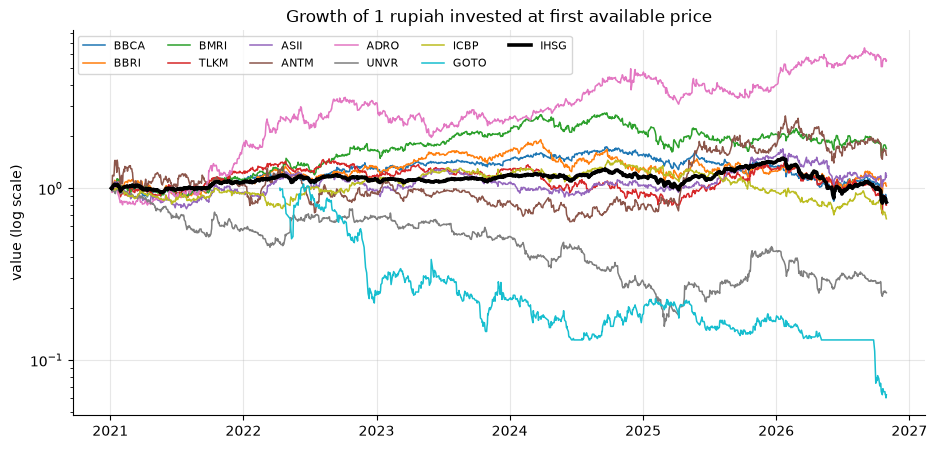

In [4]:
growth = prices.div(prices.bfill().iloc[0])
fig, ax = plt.subplots()
for c in growth.columns:
    ax.plot(growth.index, growth[c], lw=2.6 if c == "IHSG" else 1.1,
            color="black" if c == "IHSG" else None, label=c)
ax.set_title("Growth of 1 rupiah invested at first available price")
ax.set_ylabel("value (log scale)"); ax.set_yscale("log")
ax.legend(ncol=6, fontsize=8, loc="upper left"); plt.show()

## 3. Risk metrics

In [5]:
def max_drawdown(p: pd.Series) -> float:
    p = p.dropna()
    return (p / p.cummax() - 1).min()

def beta(r: pd.Series, m: pd.Series) -> float:
    df = pd.concat([r, m], axis=1).dropna()
    return np.cov(df.iloc[:, 0], df.iloc[:, 1])[0, 1] / df.iloc[:, 1].var()

ann_ret = rets.mean() * TRADING_DAYS
ann_vol = rets.std() * np.sqrt(TRADING_DAYS)
metrics = pd.DataFrame({
    "sector": pd.Series(SECTORS),
    "ann_return": ann_ret,
    "ann_volatility": ann_vol,
    "sharpe": (ann_ret - RISK_FREE) / ann_vol,
    "max_drawdown": prices.apply(max_drawdown),
    "beta_vs_IHSG": rets.apply(lambda s: beta(s, rets["IHSG"])),
}).loc[list(SECTORS) + ["IHSG"]]
metrics.loc["IHSG", "sector"] = "Index"
metrics.sort_values("sharpe", ascending=False)

,sector,ann_return,ann_volatility,sharpe,max_drawdown,beta_vs_IHSG
ADRO,Mining,0.308,0.428,0.578,-0.416,0.904
BMRI,Banks,0.095,0.310,0.114,-0.440,1.165
ANTM,Mining,0.079,0.482,0.040,-0.562,1.206
ASII,Industrials,0.030,0.313,-0.097,-0.402,0.896
BBRI,Banks,0.005,0.304,-0.181,-0.513,1.151
TLKM,Telco,-0.041,0.330,-0.306,-0.519,0.992
BBCA,Banks,-0.025,0.267,-0.320,-0.518,0.981
ICBP,Consumer,-0.074,0.274,-0.488,-0.545,0.530
IHSG,Index,-0.034,0.177,-0.530,-0.453,1.000
UNVR,Consumer,-0.252,0.399,-0.782,-0.845,0.731


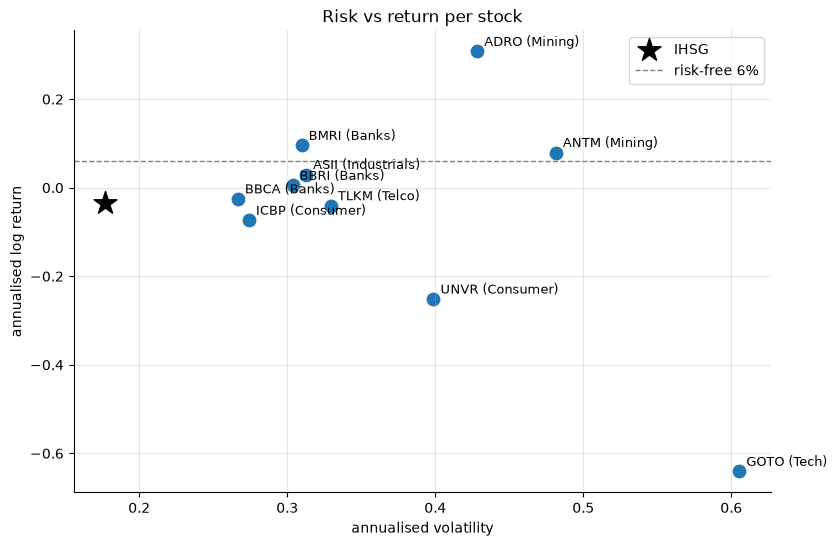

In [6]:
fig, ax = plt.subplots(figsize=(9, 6))
m = metrics.drop("IHSG")
ax.scatter(m["ann_volatility"], m["ann_return"], s=80)
for t, r in m.iterrows():
    ax.annotate(f"{t} ({r.sector})", (r.ann_volatility, r.ann_return), xytext=(5, 4), textcoords="offset points", fontsize=9)
ax.scatter(metrics.loc["IHSG", "ann_volatility"], metrics.loc["IHSG", "ann_return"], marker="*", s=300, c="black", label="IHSG")
ax.axhline(RISK_FREE, ls="--", c="grey", lw=1, label="risk-free 6%")
ax.set_xlabel("annualised volatility"); ax.set_ylabel("annualised log return")
ax.set_title("Risk vs return per stock"); ax.legend(); plt.show()

## 4. Correlation & diversification

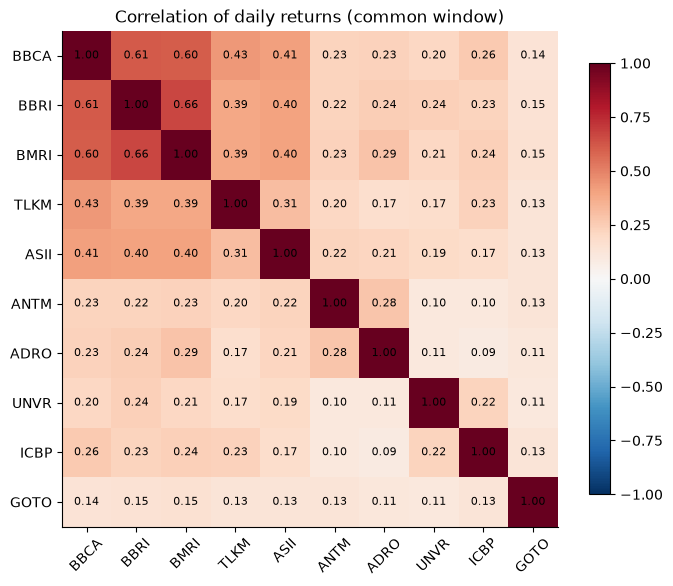

Least correlated pairs:
 ADRO  ICBP   0.090
ANTM  UNVR   0.100
      ICBP   0.100
UNVR  GOTO   0.110

Most correlated pairs:
 BBCA  TLKM   0.430
      BMRI   0.600
      BBRI   0.610
BBRI  BMRI   0.660


In [7]:
corr = common.drop(columns="IHSG").corr()
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45); ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, shrink=0.8); ax.set_title("Correlation of daily returns (common window)"); ax.grid(False); plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), 1)).stack().dropna().sort_values()
print("Least correlated pairs:\n", pairs.head(4).round(2).to_string())
print("\nMost correlated pairs:\n", pairs.tail(4).round(2).to_string())

## 5. Rolling volatility

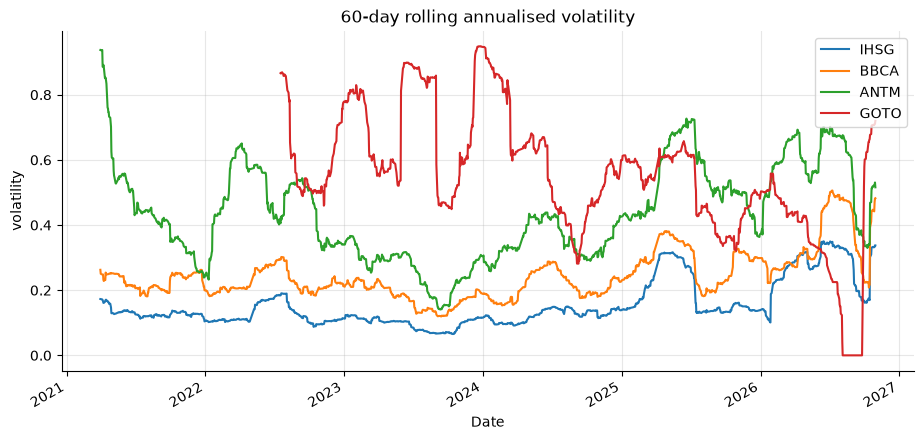

,IHSG,BBCA,ANTM,GOTO
mean,0.153,0.243,0.434,0.550
min,0.066,0.120,0.141,0.000
max,0.350,0.506,0.937,0.949


In [8]:
roll = rets[["IHSG", "BBCA", "ANTM", "GOTO"]].rolling(60).std() * np.sqrt(TRADING_DAYS)
ax = roll.plot(title="60-day rolling annualised volatility")
ax.set_ylabel("volatility"); plt.show()
roll.describe().loc[["mean", "min", "max"]]

## 6. Portfolio construction

I simulate 20,000 random long-only portfolios of the 10 stocks on the common window.
From those, I compare three choices against holding the index:
- the **max-Sharpe** portfolio
- the **minimum-volatility** portfolio
- a naive **equal-weight** portfolio

In [9]:
assets = [c for c in common.columns if c != "IHSG"]
mu = common[assets].mean() * TRADING_DAYS
cov = common[assets].cov() * TRADING_DAYS

W = RNG.dirichlet(np.ones(len(assets)), size=20_000)
p_ret = W @ mu.values
p_vol = np.sqrt(np.einsum("ij,jk,ik->i", W, cov.values, W))
p_sharpe = (p_ret - RISK_FREE) / p_vol

def stats(w):
    r = w @ mu.values; v = np.sqrt(w @ cov.values @ w)
    return r, v, (r - RISK_FREE) / v

choices = {
    "max_sharpe": W[p_sharpe.argmax()],
    "min_volatility": W[p_vol.argmin()],
    "equal_weight": np.full(len(assets), 1 / len(assets)),
}
summary = pd.DataFrame({k: stats(w) for k, w in choices.items()}, index=["ann_return", "ann_volatility", "sharpe"]).T
ihsg_r = common["IHSG"].mean() * TRADING_DAYS; ihsg_v = common["IHSG"].std() * np.sqrt(TRADING_DAYS)
summary.loc["IHSG (benchmark)"] = [ihsg_r, ihsg_v, (ihsg_r - RISK_FREE) / ihsg_v]
summary

,ann_return,ann_volatility,sharpe
max_sharpe,0.101,0.301,0.135
min_volatility,-0.039,0.193,-0.513
equal_weight,-0.076,0.206,-0.659
IHSG (benchmark),-0.082,0.188,-0.753


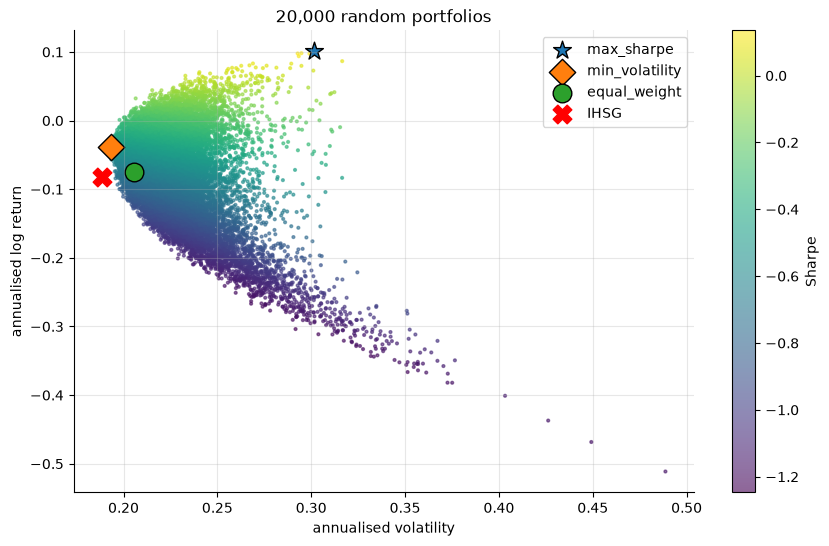

,BBCA,BBRI,BMRI,TLKM,ASII,ANTM,ADRO,UNVR,ICBP,GOTO
max_sharpe,6.6%,2.4%,3.1%,1.0%,9.4%,5.9%,62.8%,1.1%,5.5%,2.1%
min_volatility,18.1%,3.6%,6.1%,6.5%,14.1%,4.4%,7.0%,4.6%,33.1%,2.5%
equal_weight,10.0%,10.0%,10.0%,10.0%,10.0%,10.0%,10.0%,10.0%,10.0%,10.0%


In [10]:
fig, ax = plt.subplots(figsize=(10, 6))
sc = ax.scatter(p_vol, p_ret, c=p_sharpe, cmap="viridis", s=4, alpha=0.6)
for name, mk in [("max_sharpe", "*"), ("min_volatility", "D"), ("equal_weight", "o")]:
    ax.scatter(summary.loc[name, "ann_volatility"], summary.loc[name, "ann_return"], marker=mk, s=180, edgecolor="black", label=name)
ax.scatter(ihsg_v, ihsg_r, marker="X", s=180, c="red", label="IHSG")
fig.colorbar(sc, label="Sharpe"); ax.set_xlabel("annualised volatility"); ax.set_ylabel("annualised log return")
ax.set_title("20,000 random portfolios"); ax.legend(); plt.show()

pd.DataFrame(choices, index=assets).T.style.format("{:.1%}")

## 7. Monte Carlo value-at-risk (1-year horizon)

For each portfolio I bootstrap 10,000 one-year paths (252 trading days) by resampling real
historical daily returns. Bootstrapping keeps the fat tails that a normal-distribution model would smooth away.
I then read off the 5% value-at-risk (VaR) and expected shortfall (the average loss in the worst 5% of outcomes).

In [11]:
def bootstrap_paths(daily: pd.Series, n=10_000, days=TRADING_DAYS):
    idx = RNG.integers(0, len(daily), size=(n, days))
    return np.exp(daily.values[idx].sum(axis=1))   # terminal value of 1 rupiah

sims = {name: bootstrap_paths(common[assets] @ w) for name, w in choices.items()}
sims["IHSG"] = bootstrap_paths(common["IHSG"])

def risk_row(v):
    loss = 1 - v
    var5 = np.quantile(loss, 0.95)
    return {"median_value": np.median(v), "prob_of_loss": (v < 1).mean(),
            "VaR_5pct": var5, "expected_shortfall_5pct": loss[loss >= var5].mean()}

mc = pd.DataFrame({k: risk_row(v) for k, v in sims.items()}).T
mc.style.format("{:.1%}", subset=["prob_of_loss", "VaR_5pct", "expected_shortfall_5pct"]).format("{:.3f}", subset=["median_value"])

,median_value,prob_of_loss,VaR_5pct,expected_shortfall_5pct
max_sharpe,1.107,36.7%,33.0%,40.6%
min_volatility,0.968,57.1%,30.5%,36.0%
equal_weight,0.931,63.9%,34.2%,40.3%
IHSG,0.923,66.3%,32.9%,38.4%


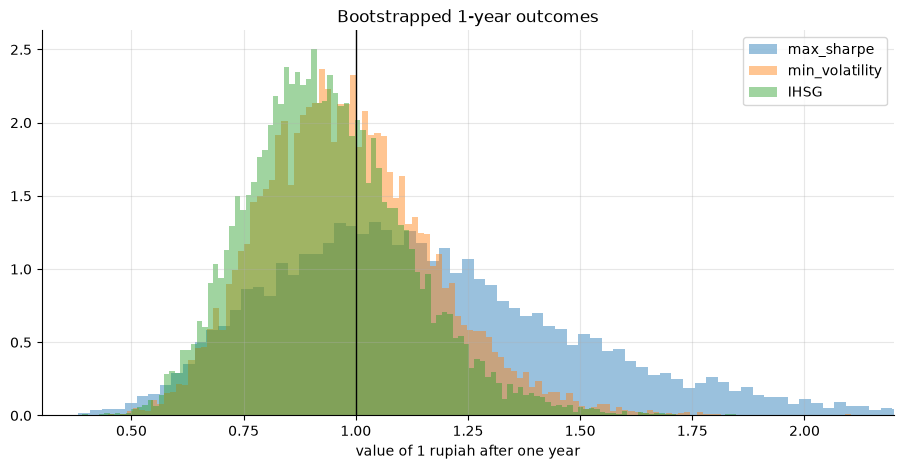

In [12]:
fig, ax = plt.subplots()
for k in ["max_sharpe", "min_volatility", "IHSG"]:
    ax.hist(sims[k], bins=120, alpha=0.45, density=True, label=k)
ax.axvline(1, c="black", lw=1)
ax.set_xlim(0.3, 2.2); ax.set_xlabel("value of 1 rupiah after one year"); ax.set_title("Bootstrapped 1-year outcomes")
ax.legend(); plt.show()

## 8. Findings

1. **The index went nowhere, then crashed.** IHSG rose from about 6,100 (Jan 2021) to a peak of about 9,130 (Jan 2026),
   then fell roughly 45% to about 5,060 by October 2026. Over the full window the annualised log return is **−3.4%**,
   well below the 6% risk-free rate. Holding the index paid less than a deposit, and paid it with more risk.
2. **Sector mattered more than "blue chip" status.**
   - Coal miner **ADRO** was the only stock with a clearly positive risk-adjusted return (≈31% a year, Sharpe 0.58).
   - **BMRI** was the best bank.
   - Consumer staples **UNVR** (−25% a year, −85% max drawdown) and **GOTO** (−64% a year, −94% max drawdown) destroyed the most value.
   - **BBCA**, often seen as the safest name, returned slightly below zero.
3. **Banks move together; mining and consumer stocks diversify.**
   - The three state and private banks correlate at 0.60–0.66.
   - ADRO–ICBP and ANTM–UNVR/ICBP correlate at only about 0.10. These are the pairs that actually diversify.
4. **Beta tells you who amplifies the market.**
   - BMRI, BBRI and ANTM have betas of about 1.15–1.2: they fall harder than IHSG in sell-offs.
   - ICBP (0.53) and UNVR (0.73) are the defensive names, by beta at least. UNVR shows that a low beta does not protect you from a stock-specific decline.
5. **Volatility comes in regimes.**
   - IHSG's 60-day volatility ranged from 7% to 35% a year.
   - GOTO's dropped to almost zero during the 119 days it sat at the IDX minimum price of Rp50, where it could not trade lower.
     That is a market-structure effect, not low risk.
6. **Diversification helped, but could not rescue a falling market.** On the common window since April 2022:
   - The **minimum-volatility** portfolio (about 33% ICBP, 18% BBCA, 14% ASII) had about the same risk as IHSG (19% vs 19%) and lost less (−3.9% vs −8.2% a year).
   - The **max-Sharpe** portfolio earned +10% a year, but only by putting about 63% in ADRO. That is a concentrated bet chosen with hindsight, not a strategy.
7. **Monte Carlo (10,000 bootstrapped years):**
   - IHSG and the equal-weight portfolio both lose money in about two out of three simulated years.
   - Every portfolio has a 5% one-year VaR of about 30–34%. Even a diversified IDX portfolio should be sized for a one-in-twenty chance of losing about a third.

---
**Caveats.**
- Past returns do not predict future returns.
- The portfolios are optimised in-sample, so their Sharpe ratios are optimistic.
- Bootstrapping assumes the days are independent, which ignores volatility clustering.
- Dividends are included only as far as Yahoo's adjusted prices reflect them.

This is an educational analysis, not investment advice.